#Create & Load the Dataset

In [ ]:
import pandas as pd

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving student_data.csv to student_data.csv


In [ ]:
df = pd.read_csv("student_data.csv")

print("Student Management System Dataset")
print("Number of students:", len(df))
print("Number of columns:", len(df.columns))

df.head()

Student Management System Dataset
Number of students: 200
Number of columns: 6


,Student_ID,Name,Attendance,Assignment_Marks,Internal_Marks,Exam_Marks
0,S001,Aarav,67,51,67,60
1,S002,Riya,74,58,56,88
2,S003,Vivaan,94,55,87,72
3,S004,Anaya,62,51,55,58
4,S005,Arjun,74,82,88,46


In [ ]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Students:")
display(df.head())

Dataset Shape: (200, 6)

Column Names:
['Student_ID', 'Name', 'Attendance', 'Assignment_Marks', 'Internal_Marks', 'Exam_Marks']

First 5 Students:


,Student_ID,Name,Attendance,Assignment_Marks,Internal_Marks,Exam_Marks
0,S001,Aarav,67,51,67,60
1,S002,Riya,74,58,56,88
2,S003,Vivaan,94,55,87,72
3,S004,Anaya,62,51,55,58
4,S005,Arjun,74,82,88,46


#Data Cleaning

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Student_ID          0
Name                0
Attendance          0
Assignment_Marks    0
Internal_Marks      0
Exam_Marks          0
dtype: int64


In [ ]:
print("Number of duplicate records:", df.duplicated().sum())

Number of duplicate records: 0


In [ ]:
print("Data Types:")
print(df.dtypes)

Data Types:
Student_ID          object
Name                object
Attendance           int64
Assignment_Marks     int64
Internal_Marks       int64
Exam_Marks           int64
dtype: object


In [ ]:
df = df.drop_duplicates()

print("Dataset after cleaning:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset after cleaning:
Rows: 200
Columns: 6


#Data Analysis

In [ ]:
#Calculate Average Marks
df["Average_Marks"] = (
    df["Assignment_Marks"] +
    df["Internal_Marks"] +
    df["Exam_Marks"]
) / 3

df["Average_Marks"] = df["Average_Marks"].round(2)

display(df[[
    "Student_ID",
    "Name",
    "Attendance",
    "Average_Marks"
]].head(10))

,Student_ID,Name,Attendance,Average_Marks
0,S001,Aarav,67,59.33
1,S002,Riya,74,67.33
2,S003,Vivaan,94,71.33
3,S004,Anaya,62,54.67
4,S005,Arjun,74,72.00
5,S006,Diya,95,81.00
6,S007,Kabir,94,71.00
7,S008,Meera,97,70.00
8,S009,Ishaan,70,79.00
9,S010,Sara,77,71.67


In [ ]:
#Calculate Performance Score
df["Performance_Score"] = (
    df["Average_Marks"] * 0.80 +
    df["Attendance"] * 0.20
)

df["Performance_Score"] = df["Performance_Score"].round(2)

display(df[[
    "Student_ID",
    "Name",
    "Average_Marks",
    "Attendance",
    "Performance_Score"
]].head(10))

,Student_ID,Name,Average_Marks,Attendance,Performance_Score
0,S001,Aarav,59.33,67,60.86
1,S002,Riya,67.33,74,68.66
2,S003,Vivaan,71.33,94,75.86
3,S004,Anaya,54.67,62,56.14
4,S005,Arjun,72.00,74,72.40
5,S006,Diya,81.00,95,83.80
6,S007,Kabir,71.00,94,75.60
7,S008,Meera,70.00,97,75.40
8,S009,Ishaan,79.00,70,77.20
9,S010,Sara,71.67,77,72.74


In [ ]:
# Classify Student Performance
def performance_category(score):
    if score >= 80:
        return "High Performance"
    elif score >= 65:
        return "Average Performance"
    else:
        return "Needs Improvement"

df["Performance_Category"] = df["Performance_Score"].apply(
    performance_category
)

display(df[[
    "Student_ID",
    "Name",
    "Performance_Score",
    "Performance_Category"
]].head(10))

,Student_ID,Name,Performance_Score,Performance_Category
0,S001,Aarav,60.86,Needs Improvement
1,S002,Riya,68.66,Average Performance
2,S003,Vivaan,75.86,Average Performance
3,S004,Anaya,56.14,Needs Improvement
4,S005,Arjun,72.40,Average Performance
5,S006,Diya,83.80,High Performance
6,S007,Kabir,75.60,Average Performance
7,S008,Meera,75.40,Average Performance
8,S009,Ishaan,77.20,Average Performance
9,S010,Sara,72.74,Average Performance


In [ ]:
# Find Class Statistics
print("Average Attendance:",
      round(df["Attendance"].mean(), 2))

print("Average Assignment Marks:",
      round(df["Assignment_Marks"].mean(), 2))

print("Average Internal Marks:",
      round(df["Internal_Marks"].mean(), 2))

print("Average Exam Marks:",
      round(df["Exam_Marks"].mean(), 2))

print("\nPerformance Categories:")
print(df["Performance_Category"].value_counts())

Average Attendance: 78.9
Average Assignment Marks: 73.46
Average Internal Marks: 72.12
Average Exam Marks: 72.54

Performance Categories:
Performance_Category
Average Performance    140
High Performance        42
Needs Improvement       18
Name: count, dtype: int64


#Data Visualization

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

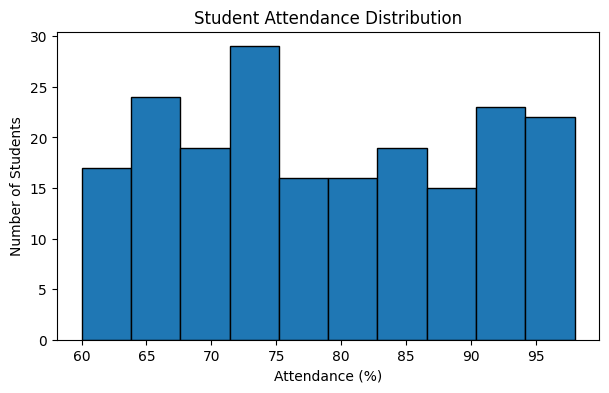

In [ ]:
# Attendance Distribution
plt.figure(figsize=(7, 4))

plt.hist(df["Attendance"], bins=10, edgecolor="black")

plt.title("Student Attendance Distribution")
plt.xlabel("Attendance (%)")
plt.ylabel("Number of Students")

plt.show()

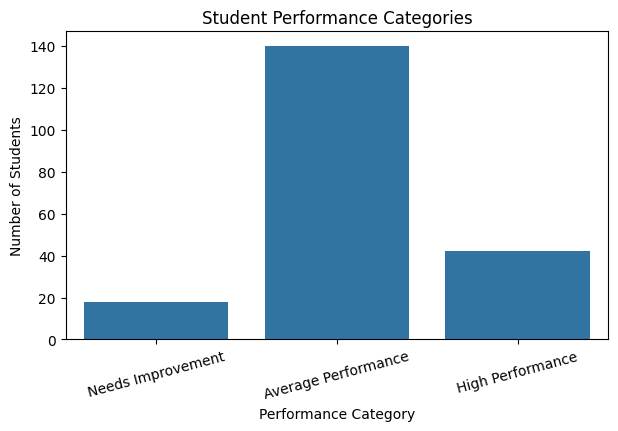

In [ ]:
# Performance Category
plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="Performance_Category")

plt.title("Student Performance Categories")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")

plt.xticks(rotation=15)
plt.show()

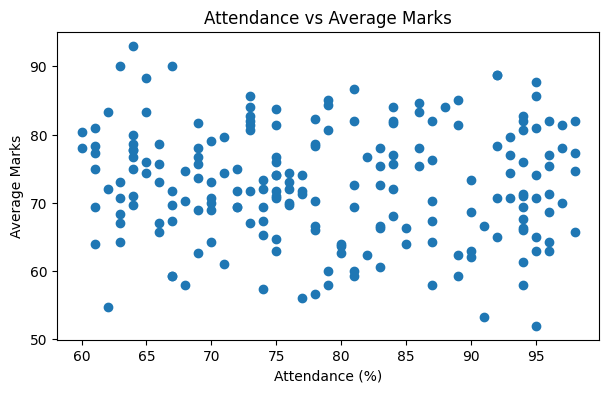

In [ ]:
# Attendance vs Average Marks
plt.figure(figsize=(7, 4))

plt.scatter(
    df["Attendance"],
    df["Average_Marks"]
)

plt.title("Attendance vs Average Marks")
plt.xlabel("Attendance (%)")
plt.ylabel("Average Marks")

plt.show()

#Hierarchical Clustering

In [ ]:
# Select features
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering

features = df[[
    "Attendance",
    "Assignment_Marks",
    "Internal_Marks",
    "Exam_Marks"
]]

In [ ]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(features)

Apply Hierarchical Clustering

In [ ]:
model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

df["Cluster"] = model.fit_predict(scaled_data)

In [ ]:
print("Student Clustering Result:")

display(df[[
    "Student_ID",
    "Name",
    "Attendance",
    "Average_Marks",
    "Cluster"
]].head(10))

Student Clustering Result:


,Student_ID,Name,Attendance,Average_Marks,Cluster
0,S001,Aarav,67,59.33,0
1,S002,Riya,74,67.33,2
2,S003,Vivaan,94,71.33,0
3,S004,Anaya,62,54.67,0
4,S005,Arjun,74,72.00,1
5,S006,Diya,95,81.00,0
6,S007,Kabir,94,71.00,0
7,S008,Meera,97,70.00,0
8,S009,Ishaan,70,79.00,1
9,S010,Sara,77,71.67,2


#Dendrogram

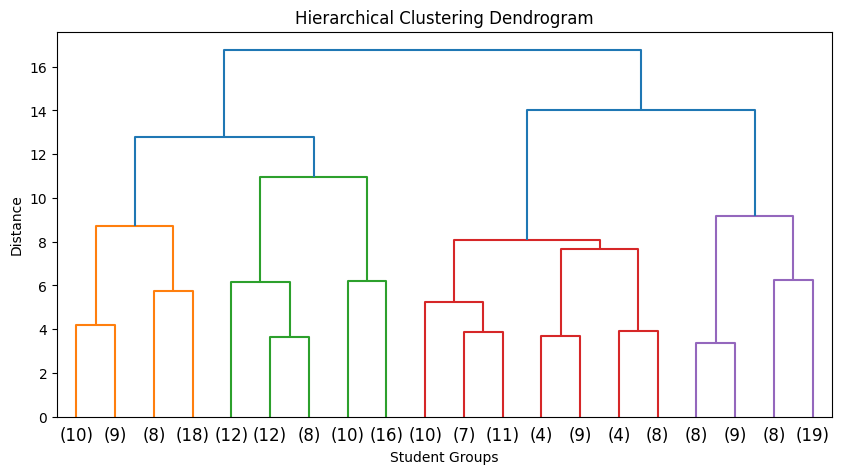

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage

linked = linkage(scaled_data, method="ward")

plt.figure(figsize=(10, 5))

dendrogram(
    linked,
    truncate_mode="lastp",
    p=20
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Student Groups")
plt.ylabel("Distance")

plt.show()

#Final Result

In [ ]:
print("Number of Students in Each Cluster:")

cluster_counts = df["Cluster"].value_counts().sort_index()

print(cluster_counts)

Number of Students in Each Cluster:
Cluster
0    103
1     44
2     53
Name: count, dtype: int64


In [ ]:
final_result = df[[
    "Student_ID",
    "Name",
    "Attendance",
    "Average_Marks",
    "Performance_Category",
    "Cluster"
]]

display(final_result.head(15))

,Student_ID,Name,Attendance,Average_Marks,Performance_Category,Cluster
0,S001,Aarav,67,59.33,Needs Improvement,0
1,S002,Riya,74,67.33,Average Performance,2
2,S003,Vivaan,94,71.33,Average Performance,0
3,S004,Anaya,62,54.67,Needs Improvement,0
4,S005,Arjun,74,72.00,Average Performance,1
5,S006,Diya,95,81.00,High Performance,0
6,S007,Kabir,94,71.00,Average Performance,0
7,S008,Meera,97,70.00,Average Performance,0
8,S009,Ishaan,70,79.00,Average Performance,1
9,S010,Sara,77,71.67,Average Performance,2


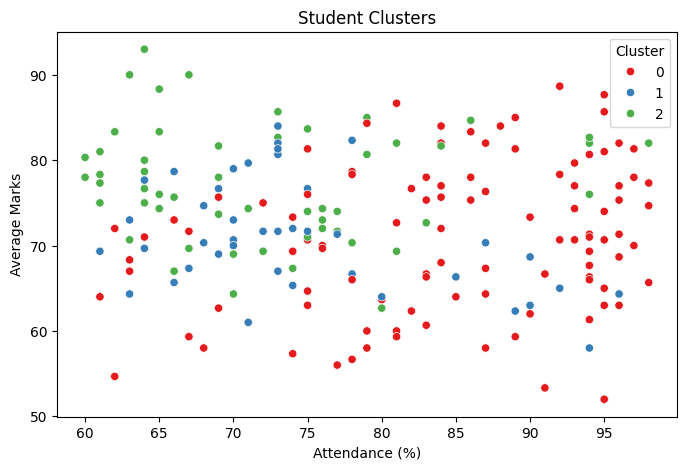

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Attendance",
    y="Average_Marks",
    hue="Cluster",
    palette="Set1"
)

plt.title("Student Clusters")
plt.xlabel("Attendance (%)")
plt.ylabel("Average Marks")

plt.show()